In this notebook we will predict survival status of passengers in the Titanic Dataset

In [2]:
#Pre-requisites
import numpy as np
import pandas as pd

Importing the data and displaying the first 10 observations

In [27]:
titanic = pd.read_csv('https://raw.githubusercontent.com/dphi-official/First_ML_Model/master/titanic.csv')
titanic.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [4]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
print("The total number of passengers in the Titanic was ",len(titanic))

The total number of passengers in the Titanic was  891


In [6]:
print("The total number of passengers who survived was ",len(titanic[titanic['Survived']==1]))

The total number of passengers who survived was  342


In [7]:
print("The total number of passengers who succummed was ",len(titanic[titanic["Survived"]==0]))

The total number of passengers who succummed was  549


Lets have a cross-tabulation of men and women who survived

In [10]:
pd.crosstab(titanic['Sex'],titanic['Survived'])

Survived,0,1
Sex,,
female,81,233
male,468,109


Survival of Passengers in each Class

In [13]:
pd.crosstab(titanic['Pclass'],titanic['Survived']==1)

Survived,False,True
Pclass,,
1,80,136
2,97,87
3,372,119


In [15]:
print("Percentage of children who survived was",np.mean(titanic['Survived'][titanic['Age'] < 18])*100)

Percentage of children who survived was 53.98230088495575


In [16]:
print("Percentage of adults who survived was",np.mean(titanic['Survived'][titanic['Age'] > 18])*100)

Percentage of adults who survived was 38.26086956521739


In [17]:
# Distribution of the genders in the titanic
titanic['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [20]:
# Crosstab distribution of genders in terms of survival
pd.crosstab(titanic['Sex'],titanic['Survived'])

Survived,0,1
Sex,,
female,81,233
male,468,109


Data Pre-processing

In [30]:
# Converting the sex column into numeric
titanic['Sex'] = titanic['Sex'].apply(lambda x: 1 if x == 'male' else 0)

In [31]:
titanic.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [32]:
# Checking for missing values
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In the age column there are missing values now imputting the Age with the mean age

In [33]:
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].mean())

In [34]:
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [35]:
titanic['Embarked'].value_counts()

,count
Embarked,
S,644
C,168
Q,77


Imputting the missing values in the column with the mode

In [38]:
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])

In [39]:
titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [40]:
titanic['Embarked'].value_counts()

,count
Embarked,
S,646
C,168
Q,77


In [41]:
titanic = titanic[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]

In [42]:
x = titanic.drop('Survived',axis = 1)
y = titanic['Survived']

In [44]:
# Splitting the Training and Testing Data
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size = 0.3, random_state = 42)

In [45]:
# Building now our ML model
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [46]:
# Now let's predict
model.predict(x_test)

array([0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0])

Evaluation of our ML model

In [47]:
from sklearn.metrics import accuracy_score
print("The training accuracy was ",accuracy_score(y_train,model.predict(x_train)))


The training accuracy was  0.9807383627608347


In [48]:
print("The testing accuracy was " , accuracy_score(y_test,model.predict(x_test)))

The testing accuracy was  0.753731343283582


In [49]:
from sklearn.tree import export_graphviz
import graphviz

In [51]:
dot_data= export_graphviz(model, out_file=None,
feature_names=x_test.columns,
class_names=['0', '1'],
filled=True, rounded=True,
special_characters=True)

In [52]:

graph = graphviz.Source(dot_data)

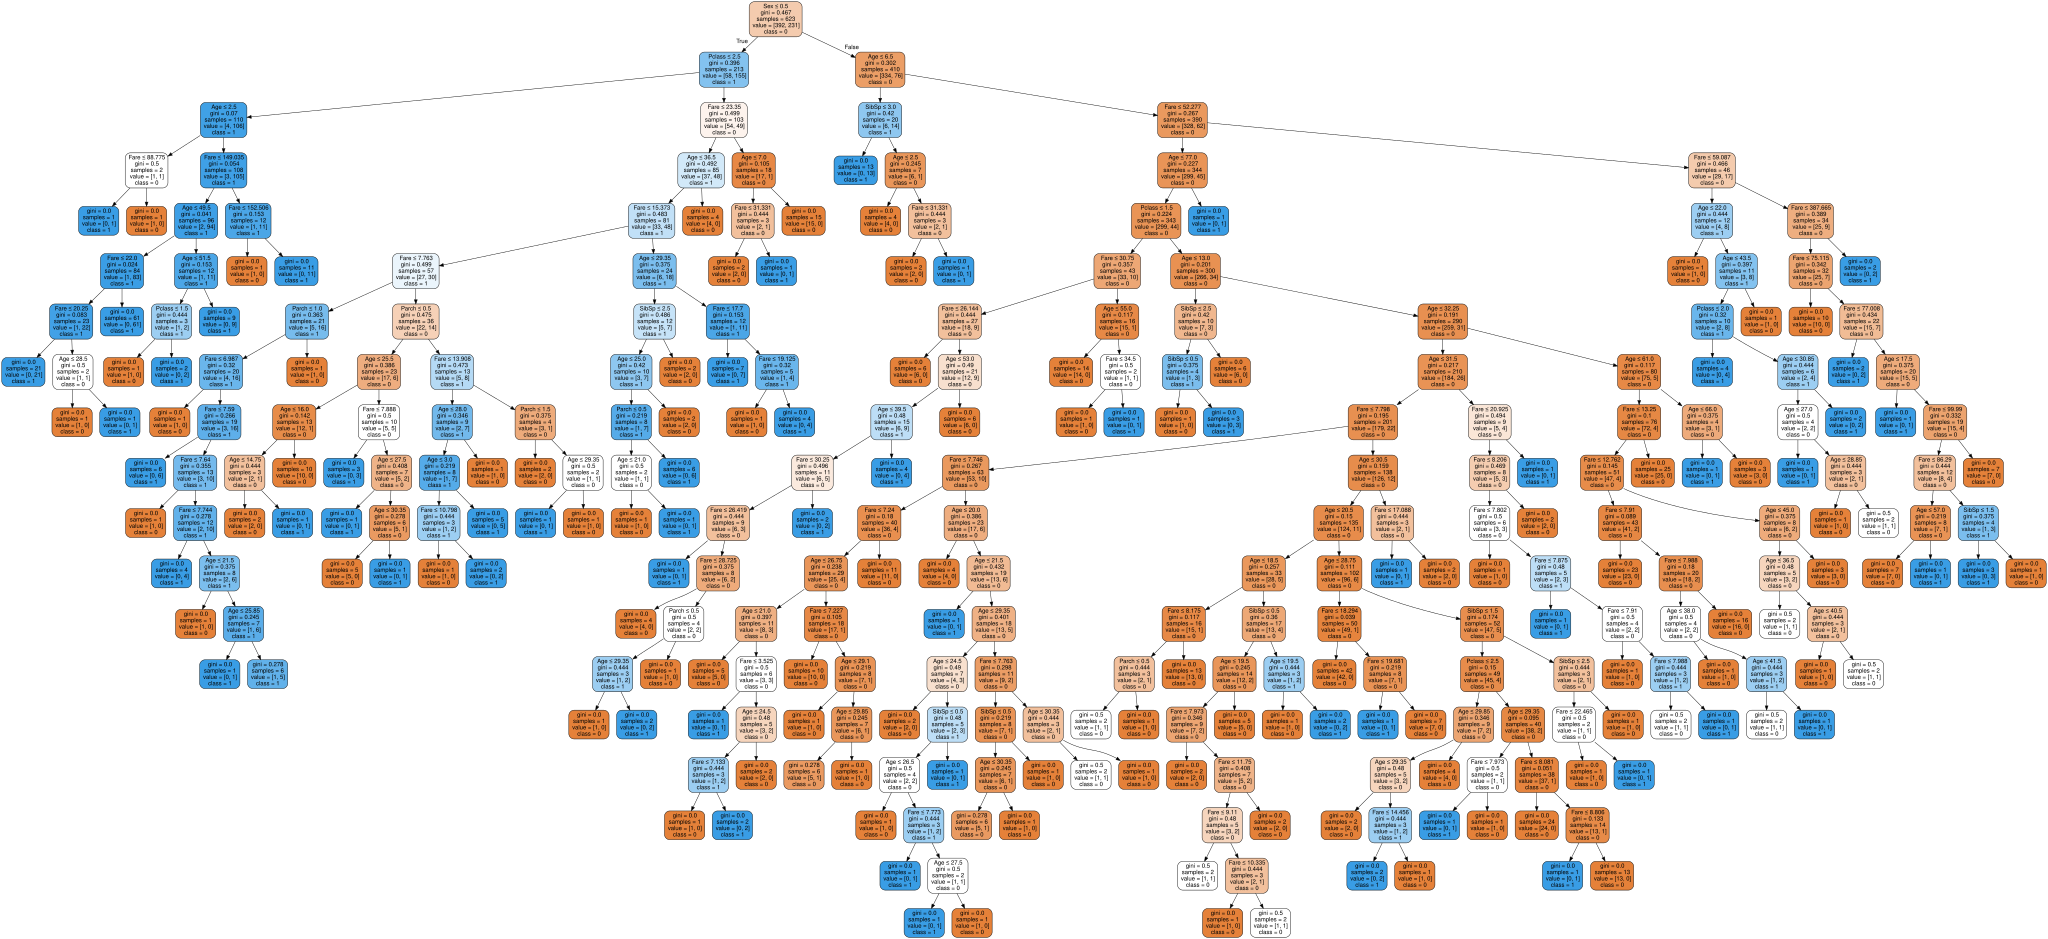

In [53]:
graph

Let's improve our model

In [54]:
model_improved = DecisionTreeClassifier(max_depth = 3)
model_improved.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=3)

In [56]:
# let's see how it's accuracy score is
print("The training accuracy score was" ,accuracy_score(y_train,model_improved.predict(x_train)))


The training accuracy score was 0.8314606741573034


In [57]:
print("The testing accuracy score was ",accuracy_score(y_test,model_improved.predict(x_test)))

The testing accuracy score was  0.8097014925373134


In [ ]:
dot_data= export_graphviz(model_improved, out_file=None,impurity=False,
feature_names=X_test.columns,
class_names=['0', '1'],
filled=True, rounded=True)

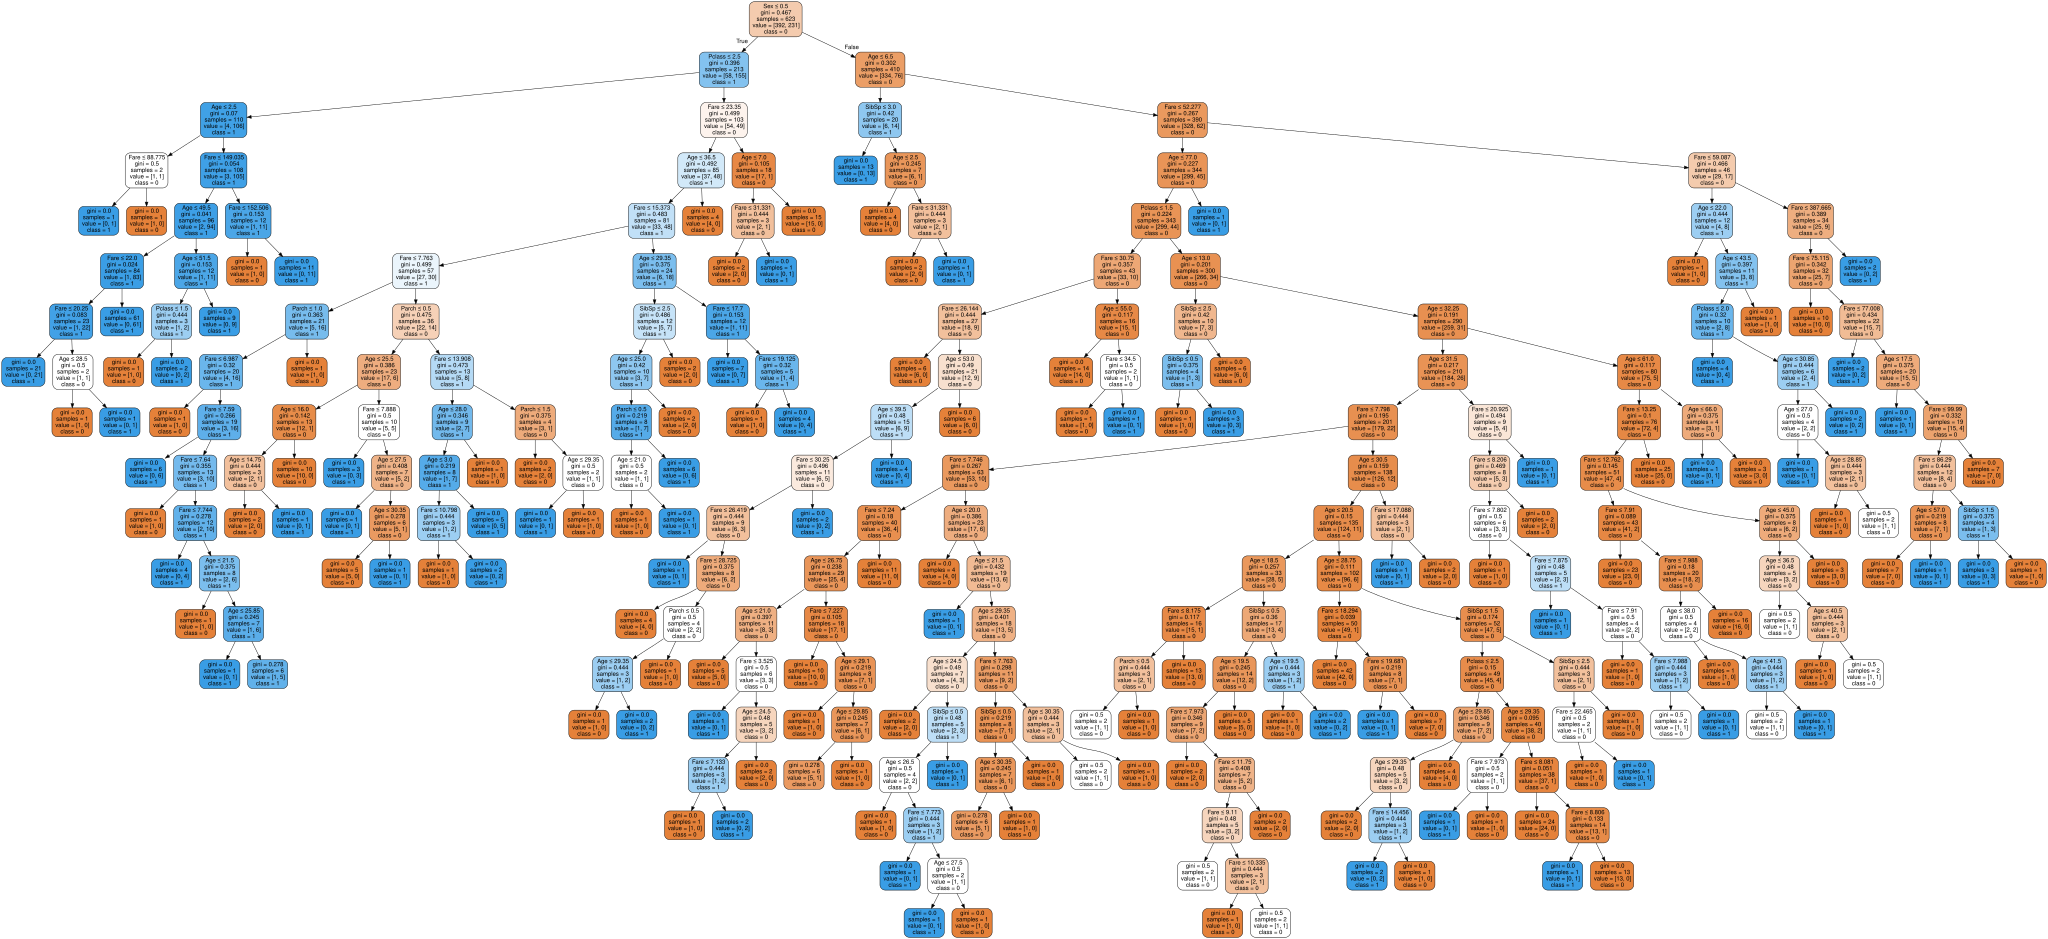

In [58]:
graph = graphviz.Source(dot_data)
graph